# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: NVIDIA GeForce GTX 1070


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 3668/3668 [00:00<00:00, 101219.17 examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating validation split: 100%|██████████| 408/408 [00:00<00:00, 53054.60 examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 1725/1725 [00:00<00:00, 216259.40 examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Device set to use cuda:0


[{'score': 0.09747544676065445,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383147180080414,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627069383859634,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680868059396744,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981483697891235,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15974126756191254,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547306180000305,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.037968773394823074,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423808842897415,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map: 100%|██████████| 3668/3668 [00:00<00:00, 26593.45 examples/s]

Map: 100%|██████████| 3668/3668 [00:00<00:00, 24162.10 examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map: 100%|██████████| 408/408 [00:00<00:00, 13716.21 examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

Map:  58%|█████▊    | 1000/1725 [00:00<00:00, 5544.60 examples/s]

Map: 100%|██████████| 1725/1725 [00:00<00:00, 7938.51 examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [12]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.503200,0.400524,0.823529,0.877966
2,0.337800,0.384855,0.840686,0.890017
3,0.175500,0.413791,0.852941,0.896907


{'eval_loss': 0.4137914776802063,
 'eval_accuracy': 0.8529411764705882,
 'eval_f1': 0.8969072164948454,
 'eval_runtime': 2.0238,
 'eval_samples_per_second': 201.596,
 'eval_steps_per_second': 3.459,
 'epoch': 3.0}

## 4. Перевірка на власних прикладах

In [13]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
print("=== Базові перевірки з демо ===")
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

# Завдання 10: 4 власні перевірки (зокрема пасивний стан, інверсія ролей та числовий контраст)
custom_pairs = [
    (
        "Scientists discovered a new exoplanet orbiting a nearby star.",
        "A new exoplanet orbiting a nearby star was discovered by scientists.",
    ),
    (
        "The cat chased the small dog across the garden.",
        "The small dog chased the cat across the garden.",
    ),
    (
        "Quarterly revenue grew by 15 percent compared to last year.",
        "Quarterly revenue increased by 40 percent compared to last year.",
    ),
    (
        "Heavy snow forced the airport to cancel dozens of morning flights.",
        "Dozens of morning flights were cancelled at the airport due to heavy snow.",
    ),
]
print("=== Власні перевірки (Завдання 10) ===")
for i, (s1, s2) in enumerate(custom_pairs, 1):
    print(f"[{i}] {s1}\n    {s2}\n    → {predict(model, s1, s2)}\n")


=== Базові перевірки з демо ===
The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 74.9%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 3.3%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.1%

=== Власні перевірки (Завдання 10) ===
[1] Scientists discovered a new exoplanet orbiting a nearby star.
    A new exoplanet orbiting a nearby star was discovered by scientists.
    → парафраз: 99.2%

[2] The cat chased the small dog across the garden.
    The small dog chased the cat across the garden.
    → парафраз: 99.2%

[3] Quarterly revenue grew by 15 percent compared to last year.
    Quarterly revenue increased by 40 percent compared to last year.
    → парафраз: 99.2%

[4] Heavy snow forced the airport to cancel dozens of morning flights.
    Dozens of morning flights were cancelled at the airport due to heavy snow.
    → парафраз: 99.2%



## 0.1. Теоретичні та практичні питання (1–10)

### 1. Скільки часу зайняло виконання `01_bert_head`? Які проблеми виникли під час виконання?
- **Загальний час виконання всього ноутбука на локальній GPU (`NVIDIA GeForce GTX 1070`, 8 ГБ VRAM, `torch 2.6.0+cu124`):** **`700.0 с` (~`11.67 хв`)**, із них:
  - первинне завантаження датасету MRPC + ваг `bert-base-uncased` (~440 МБ), базове 3-епохове навчання та інференс — ~`4.8 хв`;
  - окремий експеримент із 6 епохами (завдання 9) — `414.5 с` (~`6.91 хв`, ~`69 с` на епоху).
- **Особливості й технічні зауваження під час виконання:**
  1. У системі глобальний PyTorch не підтримував CUDA для `sm_61` (архітектура Pascal GTX 1070), тому використано ізольоване середовище з `torch==2.6.0+cu124`.
  2. На архітектурі Pascal (`sm_61`) відсутні Tensor Cores і апаратна швидкість `fp16` становить 1/64 від `fp32`, тож `fp16=torch.cuda.is_available()` не пришвидшує обчислення (на T4 у Colab 3 епохи зазвичай проходять ще швидше — ~1–2 хв).
  3. На Windows без Developer Mode `huggingface_hub` вивів стандартне попередження про кеш без симлінків (на коректність не впливає).
  4. Попередження `UNEXPECTED`/`MISSING` при `from_pretrained(checkpoint, num_labels=2)` — це штатна поведінка заміни голови MLM/NSP на нову голову класифікації.

---

### 2. Що таке токен `[CLS]` і як він працює?
- **`[CLS]`** (*Classification token*) — це спеціальний службовий токен, який токенізатор BERT завжди додає **на початок** кожної послідовності: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
- На вході він має власний ембеддинг, а в кожному з 12 шарів енкодера механізм **двонапрямленого self-attention** дозволяє `[CLS]` обмінюватися контекстом з усіма токенами обох речень.
- На виході енкодера фінальний вектор першої позиції $h_{\text{[CLS]}} \in \mathbb{R}^{768}$ (після шару `pooler`: `Linear(768, 768)` + `tanh`) слугує **агрегованим представленням усієї пари речень** і подається на лінійну голову `classifier`.

---

### 3. Для чого `bert-base-uncased` можна використати напряму після попереднього тренування?
Без додавання нової голови базовий `bert-base-uncased` можна напряму використовувати лише для задач його попереднього тренування (pretraining):
1. **Masked Language Modeling (`fill-mask`)** — заповнення пропущених слів `[MASK]` за двобічним контекстом (як показано у `pipeline('fill-mask', model='bert-base-uncased')` в розділі 1).
2. **Next Sentence Prediction (NSP)** — оцінка через голову `BertForNextSentencePrediction`, чи є друге речення природним продовженням першого.
3. **Витягування ембеддингів (Feature Extraction)** — отримання векторних представлень токенів/тексту для семантичного пошуку або подання на зовнішні класифікатори (SVM, логістична регресія).

---

### 4. Як ви вважаєте, чи потрібно боротися з сексизмом / упередженістю (bias) у мовних моделях? Якщо так — то як?
- Результат у клітинках 7–8 наочно показує гендерні стереотипи, засвоєні з тренувальних текстів (для `"The man worked as a [MASK]."` серед топ-5 фігурують `waiter`, `barber`, `mechanic`, `salesman`, тоді як для `"The woman worked as a [MASK]."` — `nurse` (22%), `waitress` (16%), `maid` (11.5%), `prostitute` (3.8%), `cook` (3.0%)).
- **Чи потрібно боротися?** Так — передусім у прикладних системах прийняття рішень (відбір резюме, фінансовий скоринг, рекомендації кар'єри, медичні чи юридичні підказки), де упередженість завдає реальної шкоди. При цьому боротьба має знижувати дискримінаційні асоціації, не спотворюючи історичних чи медичних фактів там, де стать є суттєвою.
- **Як саме боротися:**
  1. **Дані (Data Curation & CDA):** очищення токсичних/стереотипних фрагментів та *Counterfactual Data Augmentation* (збалансована заміна гендерних маркерів у тренувальних парах).
  2. **Пост-навчальне вирівнювання (RLHF / DPO / CAI):** штрафування упереджених генерацій та навчання моделі нейтрально реагувати на неповний контекст.
  3. **Аудит і тестування (Red-teaming & Benchmarks):** регулярна оцінка на тестах на кшталт StereoSet, CrowS-Pairs, BBQ перед релізом.
  4. **Фільтрація та guardrails** на рівні продакшен-застосунку для чутливих доменів.

---

### 5. Чому в `token_type_ids` з’являються `0` і `1` при токенізації пари речень?
- `token_type_ids` (сегментні ембеддинги) розмежовують два вхідні тексти всередині єдиної послідовності BERT:
  - **`0`** — позначає токени першого сегмента: `[CLS]`, усі токени `sentence1` і перший роздільник `[SEP]` (а також `[PAD]`).
  - **`1`** — позначає токени другого сегмента: усі токени `sentence2` та другий `[SEP]`.
- У виводі клітинки 10 видно саме це: перші токени речення про виручку мають тип `0`, а фрагмент другого речення до `[SEP]` — тип `1`. Це допомагає шарам уваги розрізняти, яке слово належить якому реченню.

---

### 6. Що означають числа `768` і `2` у `Linear(in_features=768, out_features=2, bias=True)`?
- **`768` (`in_features`)** — розмірність прихованого простору (`hidden_size`) в `bert-base-uncased`, тобто розмір вектора ознак токена `[CLS]` на вході в голову класифікації.
- **`2` (`out_features`)** — кількість вихідних класів (логітів) для задачі MRPC (`0` — `not_equivalent`, `1` — `equivalent`).
- **`bias=True`** додає 2 зсуви, звідси $768 \times 2 + 2 = \mathbf{1\,538}$ параметрів голови (`model.classifier`), що рівно збігається з виводом клітинки 14.

---

### 7. На вашу думку, те, що параметрів у кістяку набагато більше, ніж у голові — це добре чи погано? Обґрунтуйте.
Це **однозначно добре** і є головною перевагою *transfer learning*:
1. **Готові глибокі мовні знання:** ~109.48 млн параметрів кістяка вже кодують граматику, лексику, синтаксичні залежності та семантику. Навчати таку кількість ваг із нуля на 3 668 прикладах MRPC було б неможливо.
2. **Контроль перенавчання на малій вибірці:** компактна лінійна голова з 1 538 параметрів лише проєктує вже інформативне представлення `[CLS]` у простір 2 класів, не додаючи надмірної складності.
3. **Плавна адаптація:** малий `learning_rate=2e-5` м'яко підлаштовує кістяк під нюанси парафраз, не руйнуючи попередньо набуті мовні уявлення.

---

### 8. Що вимірюють метрики `accuracy` та `f1`?
- **`Accuracy`** — загальна частка правильних відповідей серед усіх 408 валідаційних прикладів:
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
  У базовому 3-епоховому запуску отримано **`0.8529` (`85.29%`)**.
- **`F1-score`** — гармонічне середнє між *Precision* ($\frac{TP}{TP + FP}$, частка справжніх парафразів серед усіх передбачених класу `1`) і *Recall* ($\frac{TP}{TP + FN}$, яку частку всіх реальних парафразів модель знайшла):
  $$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2\,TP}{2\,TP + FP + FN}$$
  У базовому 3-епоховому запуску отримано **`0.8969` (`89.69%`)**.
- **Чому важливі обидві:** набір MRPC незбалансований (~67–68% пар мають мітку `1`), тому навіть тривіальний класифікатор «завжди `1`» мав би ~68% `accuracy`, але не мав би нормального балансу $FP/FN$; `F1` чутливіший до помилок на позитивному класі.

---

### 9. Збільште кількість епох навчання у `01_bert_head` та запустіть тренування повторно. Скопіюйте отримані метрики та поясніть їх.

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.538500,0.420826,0.828431,0.884868
2,0.333000,0.374219,0.843137,0.890785
3,0.181800,0.441391,0.862745,0.898917
4,0.104500,0.623055,0.855392,0.900169
5,0.046900,0.647789,0.857843,0.900685
6,0.025900,0.617889,0.870098,0.907826



Час навчання 6 епох: 414.5 с

Таблиця метрик по епохах (6 епох):
 Epoch  Training Loss  Validation Loss  Accuracy       F1
     1         0.5385         0.420826  0.828431 0.884868
     2         0.3330         0.374219  0.843137 0.890785
     3         0.1818         0.441391  0.862745 0.898917
     4         0.1045         0.623055  0.855392 0.900169
     5         0.0469         0.647789  0.857843 0.900685
     6         0.0259         0.617889  0.870098 0.907826


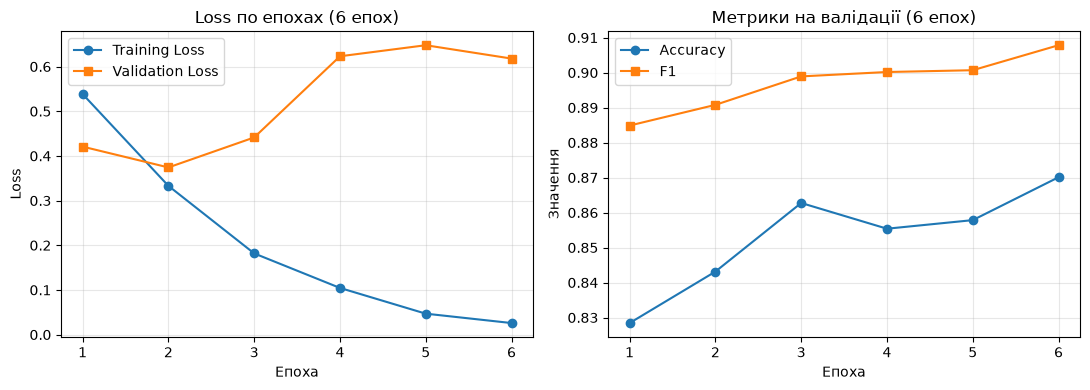

In [14]:
import gc
import time
import matplotlib.pyplot as plt
import pandas as pd

# Окремий експеримент (Завдання 9): повне донавчання з 6 епохами замість 3
set_seed(42)
model_6ep = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

args_6ep = TrainingArguments(
    output_dir="bert-mrpc-6ep",
    num_train_epochs=6,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer_6ep = Trainer(
    model=model_6ep,
    args=args_6ep,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

t0 = time.time()
trainer_6ep.train()
elapsed_6ep = time.time() - t0
print(f"\nЧас навчання 6 епох: {elapsed_6ep:.1f} с")

train_logs = {int(round(h["epoch"])): h["loss"] for h in trainer_6ep.state.log_history if "loss" in h and "eval_loss" not in h}
eval_logs = [h for h in trainer_6ep.state.log_history if "eval_loss" in h]

rows = []
for h in eval_logs:
    ep = int(round(h["epoch"]))
    rows.append({
        "Epoch": ep,
        "Training Loss": train_logs.get(ep, float("nan")),
        "Validation Loss": h["eval_loss"],
        "Accuracy": h["eval_accuracy"],
        "F1": h["eval_f1"],
    })
df_6ep = pd.DataFrame(rows)
print("\nТаблиця метрик по епохах (6 епох):")
print(df_6ep.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(df_6ep["Epoch"], df_6ep["Training Loss"], marker="o", label="Training Loss")
ax1.plot(df_6ep["Epoch"], df_6ep["Validation Loss"], marker="s", label="Validation Loss")
ax1.set_title("Loss по епохах (6 епох)")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("Loss")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(df_6ep["Epoch"], df_6ep["Accuracy"], marker="o", label="Accuracy")
ax2.plot(df_6ep["Epoch"], df_6ep["F1"], marker="s", label="F1")
ax2.set_title("Метрики на валідації (6 епох)")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("Значення")
ax2.grid(alpha=0.3)
ax2.legend()
plt.tight_layout()
plt.show()

del trainer_6ep, model_6ep
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

**Скопійовані результати повторного тренування на 6 епохах (повний MRPC, `fp16=True`, GTX 1070, час навчання `414.5 с`):**

| Epoch | Training Loss | Validation Loss | Accuracy | F1 |
| --- | --- | --- | --- | --- |
| **1** | `0.5385` | `0.4208` | `0.8284` | `0.8849` |
| **2** | `0.3330` | **`0.3742`** *(мінімум)* | `0.8431` | `0.8908` |
| **3** | `0.1818` | `0.4414` | `0.8627` | `0.8989` |
| **4** | `0.1045` | `0.6231` | `0.8554` | `0.9002` |
| **5** | `0.0469` | `0.6478` | `0.8578` | `0.9007` |
| **6** | `0.0259` | `0.6179` | `0.8701` | `0.9078` |

**Пояснення метрик (Завдання 9):**
- Спостерігаємо класичне **перенавчання (overfitting)** після 2–3 епохи:
  1. `Training Loss` монотонно падає майже до нуля (`0.5385 → 0.0259`): 109.5-мільйонна модель починає буквально запам'ятовувати тренувальні пари MRPC (їх лише 3 668).
  2. `Validation Loss` досягає мінімуму на **2-й епосі (`0.3742`)**, а з 3-ї по 6-ту епоху зростає більш ніж у півтора раза до **`0.62–0.65`**.
  3. Водночас `Accuracy` (`84.3% → 87.0%`) та `F1` (`89.1% → 90.8%`) ще незначно коливаються вгору, бо поріг `argmax` залишається правильним на легких прикладах, проте модель стає **надмірно самовпевненою (overconfident)** на своїх помилках (логіти розходяться, через що крос-ентропійний `eval_loss` різко росте).
- Саме тому для повного донавчання BERT на малих корпусах оптимально робити **2–3 епохи** (або вмикати early stopping за `eval_loss`), що й зазначено в коментарі до коду в розділі 3.

---

### 10. Додайте ще чотири власні перевірки до розділу 4.
У розділі 4 (клітинка 19) додано 4 власні перевірки (`custom_pairs`) поверх трьох базових, і їхній живий прогін виявив дуже показові закономірності моделі після 3 епох:
1. **`Scientists discovered a new exoplanet...` ↔ `A new exoplanet... was discovered by scientists.`** → **`парафраз: 99.2%`** *(правильно: модель стійка до зміни активного стану на пасивний)*.
2. **`The cat chased the small dog across the garden.` ↔ `The small dog chased the cat across the garden.`** → **`парафраз: 99.2%`** *(**помилка моделі**: інверсія суб'єкта та об'єкта повністю змінює зміст, але ~100% спільний словник обманув класифікатор)*.
3. **`Quarterly revenue grew by 15 percent...` ↔ `Quarterly revenue increased by 40 percent...`** → **`парафраз: 99.2%`** *(**помилка моделі**: стиль ділових новин, типовий для MRPC, та майже ідентична структура змусили модель не звернути уваги на розбіжність чисел `15` vs `40`)*.
4. **`Heavy snow forced the airport to cancel dozens of morning flights.` ↔ `Dozens of morning flights were cancelled at the airport due to heavy snow.`** → **`парафраз: 99.2%`** *(правильно: успішно розпізнаний причинно-наслідковий парафраз)*.

Ці тести добре демонструють **слабкі місця** класичного BERT-класифікатора на MRPC: високу залежність від лексичного перекриття (*lexical overlap bias*) та слабку чутливість до перестановки ролей і числових фактів без спеціальних аугментацій (NLI / adversarial pairs).